In [2]:

#0. 필요한 모듈 사용
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import datasets, transforms
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

In [3]:
#1. GPU 사용 환경 준비
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [4]:
#2. 가위바위보 데이터셋 전처리

# 기본 전처리를 위한 파이프라인
transform = transforms.Compose([
    #1) 이미지 크기를 224X224로 조정
    transforms.Resize((224,224)), 

    #2) 이미지를 Tensor로 변환(~225 -> 0~1)
    transforms.ToTensor(),

    #3) ImageNet 기준 채널별 표준화(빨강,초록, 파랑)
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [5]:
#3. 가위바위보 이미지 데이터 위치, 폴더 확인하기
import os

print("현재 작업 위치:", os.getcwd())
print("현재 작업 폴더:", os.listdir("."))

현재 작업 위치: c:\Users\mbc\rock
현재 작업 폴더: ['.git', 'models', 'new_paper.jpg', 'new_scissors.jpg', 'pikipick_resnet50_finetuning.pth', 'rps', 'rps-test-set', '가위바위보.ipynb']


In [6]:
#4. 데이터 구조 확인하기
import os
print("학습폴더:", os.listdir('rps'))
print("데아터폴더", os.listdir("rps-test-set"))


학습폴더: ['paper', 'rock', 'scissors']
데아터폴더 ['paper', 'rock', 'scissors']


In [7]:
#5. PyTorch 데이터셋 생성
# 이미지 데이터셋 불러오기
train_full_dataset = datasets.ImageFolder(
    root= "rps",
    transform=transform
)

test_dataset = datasets.ImageFolder(
    root= "rps-test-set",
    transform= transform
)

print("전체 학습 데이터", len(train_full_dataset))
print("테스트 데이터", len(test_dataset))
print("클래스", train_full_dataset.classes)
print("클래스 번호", train_full_dataset.class_to_idx)

전체 학습 데이터 2520
테스트 데이터 372
클래스 ['paper', 'rock', 'scissors']
클래스 번호 {'paper': 0, 'rock': 1, 'scissors': 2}


In [8]:
# 학습데이터와 검증 데이터 분리
#기존 학습이미지 2,520장을 80:20
from torch.utils.data import random_split

train_size = int(len(train_full_dataset) * 0.8)
val_size = len(train_full_dataset) - train_size

train_dataset, val_dataset = random_split(
    train_full_dataset,
    [train_size, val_size],
    generator= torch.Generator().manual_seed(42)

)
print("학습 데이터",len(train_dataset))
print("검증 데이터",len(val_dataset))
print("테스트 데이터", len(test_dataset))

학습 데이터 2016
검증 데이터 504
테스트 데이터 372


In [9]:
#5. DataLoader 생성(이미지 여러장을 묶어서 학습)

train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

In [10]:
#6. CNN 모델 라이브러리 준비

# torchvision에서 사전학습된 CNN 모델을 불러오기 위한 모듈
from torchvision import models

In [11]:
# 7. ResNet50 사전학습 가중치 선택

# ImageNet 데이터로 미리 학습된 ResNet50 가중치 사용
weights = models.ResNet50_Weights.IMAGENET1K_V2

In [12]:
# 사전학습 가중치 확인하기
print(weights)

ResNet50_Weights.IMAGENET1K_V2


In [13]:
# 8. ResNet50 사전학습 모델 불러오기

# 앞에서 선택한 ImageNet 사전학습 가중치를 적용하여 모델 생성
model = models.resnet50(weights=weights)

# 모델이 정상적으로 생성되었는지 확인
print(type(model))


<class 'torchvision.models.resnet.ResNet'>


In [14]:
# 9. ResNet50 모델의 마지막 분류층 확인

# fc(Fully Connected): CNN이 추출한 특징을 최종 분류하는 중
print(model.fc)

Linear(in_features=2048, out_features=1000, bias=True)


In [15]:
#10. ResNet50의 마지막 분류층 변경

# 기존 2048개의 특징값은 그대로 사용하고,
# 출력 클래스를 1000개에서 3개(가위, 바위, 보)로 변경
model.fc = nn.Linear(model.fc.in_features, 3)

#변경된 분류층 확인
print(model.fc)

Linear(in_features=2048, out_features=3, bias=True)


In [16]:
# 11. CNN 특징 추출층 고정(Freeze) = 새로운 fc 분류층 학습

# ImageNet에서 사전학습된 기준 CNN의 가중치를 고정
for param in model.parameters():
    param.requires_grad = False

# 가위, 바위, 보를 분류할 마지막 fc층만 학습 가능하게 설정
for param in model.fc.parameters():
    param.requires_grad = True

# 학습 가능한 파라미터수 확인
trainable = sum(p.numel() for p in model.parameters( ) if p.requires_grad)
print("학습 가능한 파라미터 수:", trainable)

학습 가능한 파라미터 수: 6147


In [17]:
# 현재 사용 중인 GPU 이름 확인
print(torch.cuda.get_device_name(0))

NVIDIA GeForce RTX 3060 Ti


In [18]:
# 13. 손실 함수와 옵티마이저 설정
# ResNet50이 가위,바위,보를 학습할 수 있도록 준비
import torch.optim as optim
#1. 예측값과 실제 정답의 차이를 계산하는 손실 함수
criterion = nn.CrossEntropyLoss()

#2. 손실을 줄이도록 학습 가능한 가중치를 수정하는 옵티마이저
optimizer = optim.Adam(
    model.fc.parameters(),
    lr=0.001
)

print("손실 함수:", criterion)
print("옵티마이저:", optimizer.__class__.__name__)

손실 함수: CrossEntropyLoss()
옵티마이저: Adam


In [19]:
# 14번 모델 검증이 되지 않아 ResNet50을 cpu->GPU
# ResNet50 모델을 GPU로 이동 

# 학습 시작 전 모델과 데이터의 장치 통일
model = model.to(device)

# 모델과 GPU 연결 확인
print("모델 위치:", next(model.parameters()).device)
print("사용 장치:", device)

모델 위치: cuda:0
사용 장치: cuda


In [20]:
# 14. ResNet50 CNN 모델 학습 및 검증

epochs = 5  # 전체 학습 데이터를 5번 반복 학습

for epoch in range(epochs):

    # ==========================
    # 1. 학습(Training)
    # ==========================
    model.eval()  # 고정된 ResNet50의 BatchNorm 통계 유지
    model.fc.train()  # 마지막 분류층 학습

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        # 이미지와 정답을 GPU로 이동
        images = images.to(device)
        labels = labels.to(device)

        # 이전 기울기 초기화
        optimizer.zero_grad()

        # 예측 → 손실 계산 → 역전파 → 가중치 수정
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        # 손실 및 정확도 계산
        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # ==========================
    # 2. 검증(Validation)
    # ==========================
    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    # ==========================
    # 3. 결과 출력
    # ==========================
    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total
    avg_loss = train_loss / train_total

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Loss: {avg_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/5] Loss: 0.6197 | Train Acc: 89.38% | Val Acc: 98.02%
Epoch [2/5] Loss: 0.2520 | Train Acc: 99.40% | Val Acc: 100.00%
Epoch [3/5] Loss: 0.1494 | Train Acc: 99.90% | Val Acc: 100.00%
Epoch [4/5] Loss: 0.1023 | Train Acc: 99.95% | Val Acc: 100.00%
Epoch [5/5] Loss: 0.0760 | Train Acc: 100.00% | Val Acc: 100.00%


In [21]:
# 테스트 데이터셋이 만들어져 있는지 확인
print(len(test_dataset))

# 15번 테스트 데이터를 평가하기 전 테스트 로더를 만들지 않고 실행 생성하기
from torch.utils.data import DataLoader

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

print("테스트 이미지 수:", len(test_dataset))
print("테스트 배치 수:", len(test_loader))


372
테스트 이미지 수: 372
테스트 배치 수: 12


In [22]:
# 15. 테스트 데이터로 CNN 모델 성능 평가

model.eval()  # 모델을 평가 모드로 변경

test_correct = 0
test_total = 0

with torch.no_grad():  # 평가할 때는 가중치를 학습하지 않음
    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        test_correct += (predictions == labels).sum().item()
        test_total += labels.size(0)

test_acc = 100 * test_correct / test_total

print(f"테스트 정확도: {test_acc:.2f}%")
print(f"정답 개수: {test_correct}/{test_total}")

테스트 정확도: 79.03%
정답 개수: 294/372


In [23]:
# 16. 테스트 이미지 불러오기
from torchvision import datasets

test_dataset = datasets.ImageFolder(
    root="rps-test-set",
    transform=transform
)

In [24]:
# 17. 클래스별 테스트 정확도 확인 - 어떤 손동작을 가장 많이 틀렸는지 확인하기

model.eval()

class_correct = [0, 0, 0]
class_total = [0, 0, 0]

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        for label, prediction in zip(labels, predictions):
            idx = label.item()
            class_total[idx] += 1

            if label == prediction:
                class_correct[idx] += 1

# 클래스별 정확도 출력
for i, class_name in enumerate(test_dataset.classes):
    accuracy = 100 * class_correct[i] / class_total[i]
    print(f"{class_name}: {accuracy:.2f}% "
          f"({class_correct[i]}/{class_total[i]})")

paper: 42.74% (53/124)
rock: 100.00% (124/124)
scissors: 94.35% (117/124)


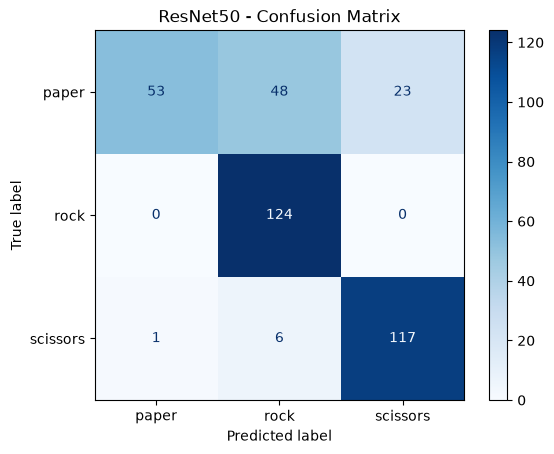

In [25]:
# 18. 혼동행렬로 오분류 확인

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model.eval()

y_true = []  # 실제 정답
y_pred = []  # 모델 예측

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.tolist())
        y_pred.extend(predictions.cpu().tolist())

# 혼동행렬 계산
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

# 시각화
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=test_dataset.classes
)

disp.plot(cmap="Blues")
plt.title("ResNet50 - Confusion Matrix")
plt.show()

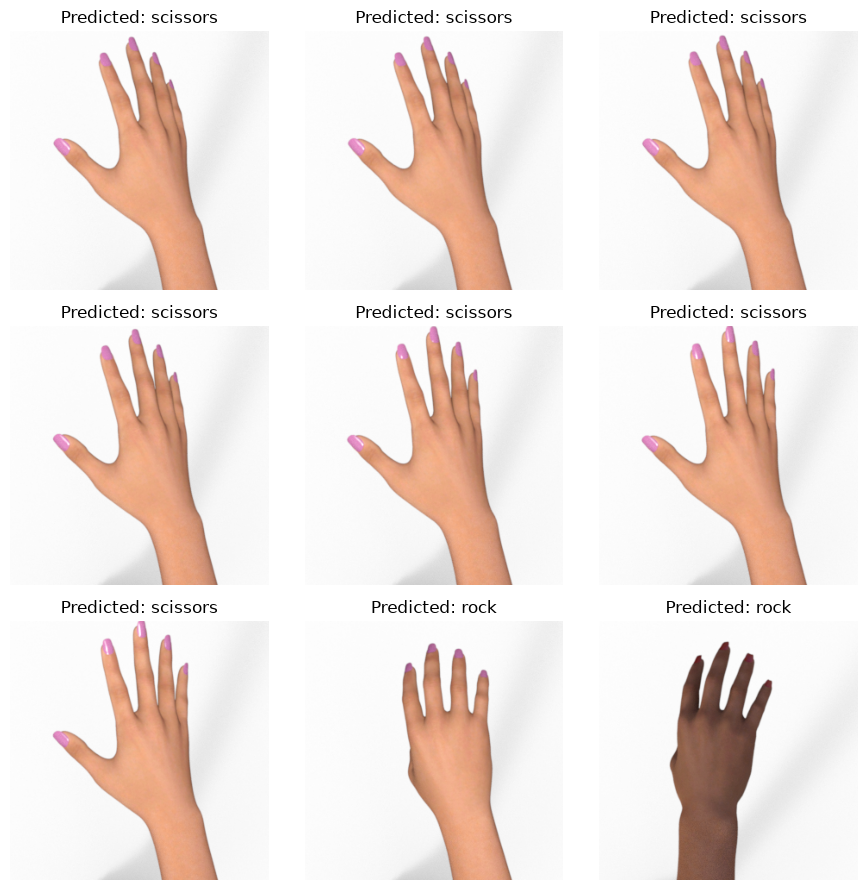

In [26]:
# 19. 잘못 예측한 보 이미지 확인

from PIL import Image
import matplotlib.pyplot as plt

model.eval()

wrong_paper = []

for path, label in test_dataset.samples:
    if test_dataset.classes[label] != "paper":
        continue

    image = Image.open(path).convert("RGB")
    tensor = transform(image).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(tensor)
        pred = output.argmax(dim=1).item()

    if pred != label:
        wrong_paper.append((image, test_dataset.classes[pred]))

# 오분류된 보 이미지 9장 확인
n = min(9, len(wrong_paper))

fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for ax in axes.flat:
    ax.axis("off")

for i in range(n):
    image, predicted = wrong_paper[i]
    axes.flat[i].imshow(image)
    axes.flat[i].set_title(f"Predicted: {predicted}")

plt.tight_layout()
plt.show()

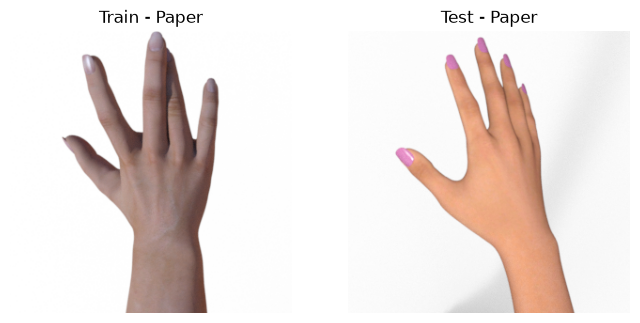

In [27]:
# 20. 학습용 보 이미지와 테스트용 보 이미지 비교

from PIL import Image
import matplotlib.pyplot as plt

train_path = train_full_dataset.samples[
    next(i for i, (_, label) in enumerate(train_full_dataset.samples)
         if train_full_dataset.classes[label] == "paper")
][0]

test_path = test_dataset.samples[
    next(i for i, (_, label) in enumerate(test_dataset.samples)
         if test_dataset.classes[label] == "paper")
][0]

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(Image.open(train_path))
axes[0].set_title("Train - Paper")

axes[1].imshow(Image.open(test_path))
axes[1].set_title("Test - Paper")

for ax in axes:
    ax.axis("off")

plt.show()

In [28]:
# 21. 학습 데이터 증강 설정 => 학습 데이터 전용 train_transform 새롭게 만들기

train_transform = transforms.Compose([
    # 이미지 크기 조정
    transforms.Resize((224, 224)),

    # 손 방향을 조금씩 회전
    transforms.RandomRotation(degrees=15),

    # 이미지 밝기와 대비 변화
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2
    ),

    # 이미지를 Tensor로 변환
    transforms.ToTensor(),

    # ImageNet 기준 RGB 채널별 정규화
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


In [29]:
# 22. 학습 데이터에만 데이터 증강 적용
# 기존 학습 2,016장/ 검증 504장 분할 유지

from torch.utils.data import Subset

# 기존 학습·검증 데이터의 인덱스 유지
train_indices = train_dataset.indices
val_indices = val_dataset.indices

# 학습용: 데이터 증강 적용
augmented_dataset = datasets.ImageFolder(
    root="rps",
    transform=train_transform
)

# 검증용: 기존 전처리만 적용 (증강 X)
validation_dataset = datasets.ImageFolder(
    root="rps",
    transform=transform
)

# 기존 분할 인덱스를 사용해 데이터셋 재구성
train_dataset = Subset(augmented_dataset, train_indices)
val_dataset = Subset(validation_dataset, val_indices)

print("학습 이미지:", len(train_dataset))
print("검증 이미지:", len(val_dataset))

학습 이미지: 2016
검증 이미지: 504


In [30]:
# 23. 데이터 증강 적용 후 DataLoader 재생성

from torch.utils.data import DataLoader

# 1. 학습용 DataLoader (데이터 증강 O)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True
)

# 2. 검증용 DataLoader (데이터 증강 X)
val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False
)

# 3. 테스트용 DataLoader (데이터 증강 X)
test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False
)

# 배치 개수 확인
print("Train:", len(train_loader))
print("Validation:", len(val_loader))
print("Test:", len(test_loader))

Train: 63
Validation: 16
Test: 12


In [31]:
# 24. 데이터 증강 실험용 ResNet50 모델 생성

# 실험 결과의 재현성을 높이기 위한 시드 설정
torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# 동일한 ImageNet 사전학습 모델 불러오기
model_aug = models.resnet50(weights=weights)

# 기존 특징 추출층 고정
for param in model_aug.parameters():
    param.requires_grad = False

# 마지막 분류층을 3개로 변경
model_aug.fc = nn.Linear(model_aug.fc.in_features, 3)

# GPU로 이동
model_aug = model_aug.to(device)

print(model_aug.fc)
print("모델 위치:", next(model_aug.parameters()).device)

Linear(in_features=2048, out_features=3, bias=True)
모델 위치: cuda:0


In [32]:
# 25. 데이터 증강 모델의 손실 함수 및 옵티마이저 설정

# 예측값과 실제 정답의 차이를 계산
criterion_aug = nn.CrossEntropyLoss()

# 손실을 줄이도록 마지막 분류층의 가중치를 수정
optimizer_aug = optim.Adam(
    model_aug.fc.parameters(),
    lr=0.001
)

print("손실 함수:", criterion_aug)
print("옵티마이저:", optimizer_aug.__class__.__name__)

손실 함수: CrossEntropyLoss()
옵티마이저: Adam


In [33]:
# 26. 데이터 증강 ResNet50 모델 학습 (5 Epoch)

epochs = 5

# Epoch별 결과 저장
train_losses_aug = []
train_accs_aug = []
val_accs_aug = []

for epoch in range(epochs):

    # 1. 학습
    model_aug.eval()  # 고정된 CNN의 BatchNorm 통계 유지
    model_aug.fc.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:

        # 이미지와 정답을 GPU로 이동
        images = images.to(device)
        labels = labels.to(device)

        # 이전 기울기 초기화
        optimizer_aug.zero_grad()

        # 예측 → 손실 계산 → 역전파 → 가중치 수정
        outputs = model_aug(images)
        loss = criterion_aug(outputs, labels)

        loss.backward()
        optimizer_aug.step()

        # 학습 손실 및 정확도 계산
        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # 2. 검증
    model_aug.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_aug(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    # 3. Epoch별 결과 계산
    avg_loss = train_loss / train_total
    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    # 결과 저장
    train_losses_aug.append(avg_loss)
    train_accs_aug.append(train_acc)
    val_accs_aug.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Loss: {avg_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/5] | Loss: 0.6372 | Train Acc: 84.33% | Val Acc: 96.43%
Epoch [2/5] | Loss: 0.2813 | Train Acc: 97.52% | Val Acc: 96.83%
Epoch [3/5] | Loss: 0.1858 | Train Acc: 98.46% | Val Acc: 97.62%
Epoch [4/5] | Loss: 0.1425 | Train Acc: 98.96% | Val Acc: 98.41%
Epoch [5/5] | Loss: 0.1084 | Train Acc: 99.21% | Val Acc: 97.62%


In [34]:
# 27. 데이터 증강 모델 테스트 평가

# 학습이 끝난 모델을 평가 모드로 변경
model_aug.eval()

test_correct_aug = 0
test_total_aug = 0

with torch.no_grad():
    for images, labels in test_loader:

        # 이미지와 정답을 GPU로 이동
        images = images.to(device)
        labels = labels.to(device)

        # 모델 예측
        outputs = model_aug(images)
        predictions = outputs.argmax(dim=1)

        # 정답 개수 계산
        test_correct_aug += (predictions == labels).sum().item()
        test_total_aug += labels.size(0)

# 전체 테스트 정확도
test_acc_aug = 100 * test_correct_aug / test_total_aug

print(f"기존 모델 정확도: {test_acc:.2f}%")
print(f"증강 모델 정확도: {test_acc_aug:.2f}%")
print(f"정답 개수: {test_correct_aug}/{test_total_aug}")

기존 모델 정확도: 79.03%
증강 모델 정확도: 74.73%
정답 개수: 278/372


In [35]:
# 28. 증강 모델의 가위·바위·보 정확도 확인

model_aug.eval()

class_correct_aug = [0, 0, 0]
class_total_aug = [0, 0, 0]

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_aug(images)
        predictions = outputs.argmax(dim=1)

        for label, pred in zip(labels, predictions):
            idx = label.item()
            class_total_aug[idx] += 1

            if label == pred:
                class_correct_aug[idx] += 1

for i, name in enumerate(test_dataset.classes):
    acc = 100 * class_correct_aug[i] / class_total_aug[i]
    print(f"{name}: {acc:.2f}% "
          f"({class_correct_aug[i]}/{class_total_aug[i]})")

paper: 37.10% (46/124)
rock: 100.00% (124/124)
scissors: 87.10% (108/124)


In [36]:
# 세번째  테스트 - ResNet50의 일부 특징 추출층을 미세조정(Fine-tuning)
# 29. Fine-tuning용 ResNet50 모델 생성

torch.manual_seed(42)
torch.cuda.manual_seed_all(42)

# 사전학습된 ResNet50 불러오기
model_ft = models.resnet50(weights=weights)

# 1. 기존 CNN 전체 가중치 고정
for param in model_ft.parameters():
    param.requires_grad = False

# 2. 마지막 특징 추출 블록(layer4) 학습 허용
for param in model_ft.layer4.parameters():
    param.requires_grad = True

# 3. 마지막 분류층을 가위·바위·보 3개로 변경
model_ft.fc = nn.Linear(model_ft.fc.in_features, 3)

# 4. GPU로 이동
model_ft = model_ft.to(device)

print("분류층:", model_ft.fc)
print("실행 장치:", next(model_ft.parameters()).device)

분류층: Linear(in_features=2048, out_features=3, bias=True)
실행 장치: cuda:0


In [37]:
# 30. Fine-tuning 손실 함수 및 옵티마이저 설정
import torch.optim as optim

# 예측값과 정답의 차이 계산
criterion_ft = nn.CrossEntropyLoss()

# layer4와 fc에 서로 다른 학습률 적용
optimizer_ft = optim.Adam([
    {"params": model_ft.layer4.parameters(), "lr": 0.00001},
    {"params": model_ft.fc.parameters(), "lr": 0.0001}
])

print("손실 함수:", criterion_ft)
print("옵티마이저:", optimizer_ft.__class__.__name__)

for i, group in enumerate(optimizer_ft.param_groups):
    print(f"그룹 {i+1} 학습률: {group['lr']}")
    

손실 함수: CrossEntropyLoss()
옵티마이저: Adam
그룹 1 학습률: 1e-05
그룹 2 학습률: 0.0001


In [38]:
# 31. ResNet50 Fine-tuning 모델 학습 및 검증

epochs = 5

# Epoch별 학습 결과 저장
train_losses_ft = []
train_accs_ft = []
val_accs_ft = []

for epoch in range(epochs):

    # 1. 학습 모드 설정
    model_ft.eval()          # 고정된 BatchNorm 통계 유지
    model_ft.layer4.train()  # layer4 미세조정
    model_ft.fc.train()      # 최종 분류층 학습

    # layer4의 BatchNorm은 평가 모드 유지
    for module in model_ft.layer4.modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    # 2. 학습
    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_ft.zero_grad()

        # 예측 → 손실 계산 → 역전파 → 가중치 업데이트
        outputs = model_ft(images)
        loss = criterion_ft(outputs, labels)

        loss.backward()
        optimizer_ft.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # 3. 검증
    model_ft.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_ft(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    # 4. Epoch별 결과 계산
    avg_loss = train_loss / train_total
    train_acc = 100 * train_correct / train_total
    val_acc = 100 * val_correct / val_total

    train_losses_ft.append(avg_loss)
    train_accs_ft.append(train_acc)
    val_accs_ft.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] | "
        f"Loss: {avg_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/5] | Loss: 0.6708 | Train Acc: 79.86% | Val Acc: 94.44%
Epoch [2/5] | Loss: 0.0343 | Train Acc: 99.55% | Val Acc: 100.00%
Epoch [3/5] | Loss: 0.0080 | Train Acc: 99.85% | Val Acc: 99.80%
Epoch [4/5] | Loss: 0.0029 | Train Acc: 100.00% | Val Acc: 100.00%
Epoch [5/5] | Loss: 0.0024 | Train Acc: 99.95% | Val Acc: 100.00%


In [39]:
# 32. Fine-tuning 모델 저장

torch.save({
    "model_state_dict": model_ft.state_dict(),
    "class_to_idx": test_dataset.class_to_idx,
    "epochs": epochs,
    "train_acc": train_accs_ft[-1],
    "val_acc": val_accs_ft[-1]
}, "pikipick_resnet50_finetuning.pth")

print("Fine-tuning 모델 저장 완료!")

Fine-tuning 모델 저장 완료!


In [40]:
# 33. Fine-tuning 모델 검증 정확도 확인

model_ft.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_ft(images)
        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

val_acc_ft = 100 * correct / total

print(f"Fine-tuning 검증 정확도: {val_acc_ft:.2f}%")
print(f"정답 개수: {correct}/{total}")


Fine-tuning 검증 정확도: 100.00%
정답 개수: 504/504


In [41]:
# 35. Fine-tuning 모델의 테스트 정확도 평가

model_ft.eval()

test_correct_ft = 0
test_total_ft = 0

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_ft(images)
        predictions = outputs.argmax(dim=1)

        test_correct_ft += (predictions == labels).sum().item()
        test_total_ft += labels.size(0)

test_acc_ft = 100 * test_correct_ft / test_total_ft

print(f"Fine-tuning 테스트 정확도: {test_acc_ft:.2f}%")
print(f"정답 개수: {test_correct_ft}/{test_total_ft}")


Fine-tuning 테스트 정확도: 94.35%
정답 개수: 351/372


In [42]:
# 36. Fine-tuning 모델의 클래스별 정확도 확인

model_ft.eval()

class_correct_ft = [0, 0, 0]
class_total_ft = [0, 0, 0]

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_ft(images)
        predictions = outputs.argmax(dim=1)

        for label, pred in zip(labels, predictions):
            idx = label.item()
            class_total_ft[idx] += 1

            if label == pred:
                class_correct_ft[idx] += 1

for i, name in enumerate(test_dataset.classes):
    acc = 100 * class_correct_ft[i] / class_total_ft[i]
    print(f"{name}: {acc:.2f}% "
          f"({class_correct_ft[i]}/{class_total_ft[i]})")
    

paper: 98.39% (122/124)
rock: 100.00% (124/124)
scissors: 84.68% (105/124)


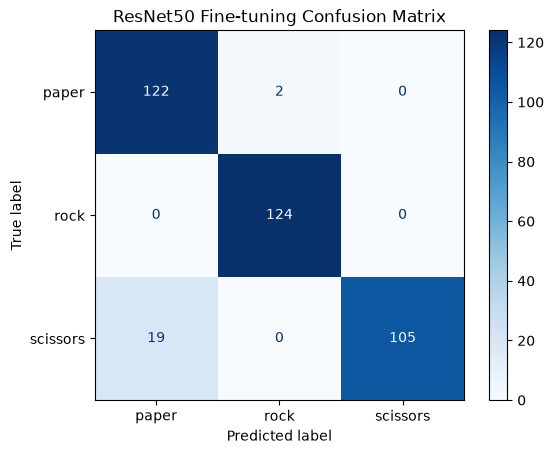

In [43]:
# 37. Fine-tuning 모델 혼동행렬 확인

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

model_ft.eval()

y_true_ft = []
y_pred_ft = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_ft(images)
        predictions = outputs.argmax(dim=1)

        y_true_ft.extend(labels.tolist())
        y_pred_ft.extend(predictions.cpu().tolist())

cm_ft = confusion_matrix(
    y_true_ft,
    y_pred_ft,
    labels=[0, 1, 2]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ft,
    display_labels=test_dataset.classes
)

disp.plot(cmap="Blues")
plt.title("ResNet50 Fine-tuning Confusion Matrix")
plt.show()

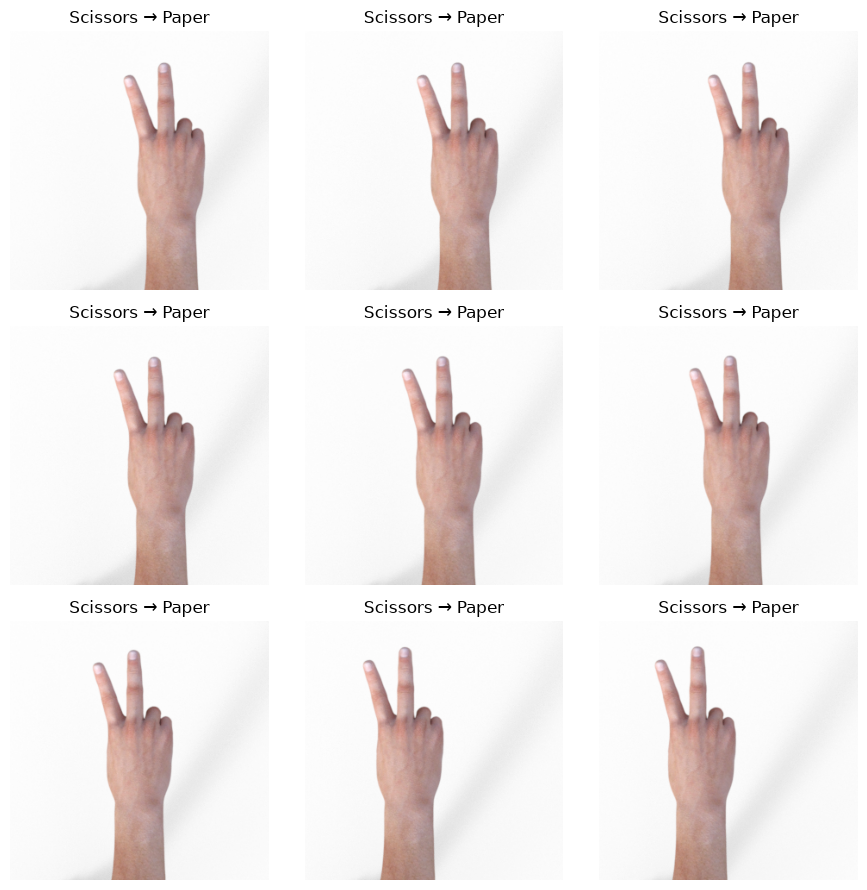

In [44]:
# 38. 가위(scissors)를 보(paper)로 잘못 예측한 이미지 확인

from PIL import Image
import matplotlib.pyplot as plt

model_ft.eval()

wrong_scissors = []

with torch.no_grad():
    for path, label in test_dataset.samples:

        # 실제 정답이 가위인 이미지만 확인
        if test_dataset.classes[label] != "scissors":
            continue

        image = Image.open(path).convert("RGB")
        image_tensor = transform(image).unsqueeze(0).to(device)

        # Fine-tuning 모델 예측
        outputs = model_ft(image_tensor)
        pred = outputs.argmax(dim=1).item()

        # 가위를 보로 잘못 예측한 경우 저장
        if test_dataset.classes[pred] == "paper":
            wrong_scissors.append(image)

# 오분류된 이미지 최대 9장 출력
fig, axes = plt.subplots(3, 3, figsize=(9, 9))

for ax in axes.flat:
    ax.axis("off")

for i, image in enumerate(wrong_scissors[:9]):
    axes.flat[i].imshow(image)
    axes.flat[i].set_title("Scissors → Paper")

plt.tight_layout()
plt.show()

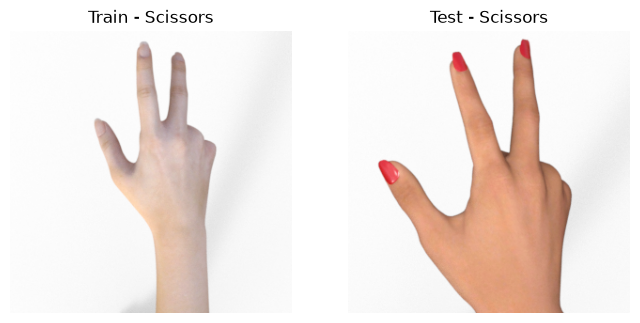

In [45]:
# 39. 학습용과 테스트용 가위 이미지 비교

from PIL import Image
import matplotlib.pyplot as plt

# 학습용 가위 이미지 1장
train_scissors = next(
    path for path, label in train_full_dataset.samples
    if train_full_dataset.classes[label] == "scissors"
)

# 오분류된 테스트 가위 이미지 1장
test_scissors = next(
    path for path, label in test_dataset.samples
    if test_dataset.classes[label] == "scissors"
    and path in [
        p for p, lbl in test_dataset.samples
        if test_dataset.classes[lbl] == "scissors"
    ]
)

fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(Image.open(train_scissors))
axes[0].set_title("Train - Scissors")

axes[1].imshow(Image.open(test_scissors))
axes[1].set_title("Test - Scissors")

for ax in axes:
    ax.axis("off")

plt.show()

In [46]:
# 40. Fine-tuning 최종 모델 저장

import torch
import os

# 모델을 저장할 폴더 생성
os.makedirs("models", exist_ok=True)

# 저장할 파일 경로
save_path = "models/pikipick_resnet50_ft_v1.pth"

# 모델 가중치와 학습 정보 저장
torch.save({
    "model_state_dict": model_ft.state_dict(),
    "class_to_idx": test_dataset.class_to_idx,
    "model_name": "ResNet50",
    "epochs": 5,
    "val_accuracy": 100.0,
    "test_accuracy": 94.35
}, save_path)

print("모델 저장 완료!")
print("저장 위치:", os.path.abspath(save_path))
print("파일 크기:", round(os.path.getsize(save_path) / (1024**2), 2), "MB")

모델 저장 완료!
저장 위치: c:\Users\mbc\rock\models\pikipick_resnet50_ft_v1.pth
파일 크기: 90.01 MB


In [47]:
# 현재 Jupyter 작업 위치와 파일 확인
import os

print("현재 작업 위치:", os.getcwd())
print("현재 폴더 파일:", os.listdir())

현재 작업 위치: c:\Users\mbc\rock
현재 폴더 파일: ['.git', 'models', 'new_paper.jpg', 'new_scissors.jpg', 'pikipick_resnet50_finetuning.pth', 'rps', 'rps-test-set', '가위바위보.ipynb']


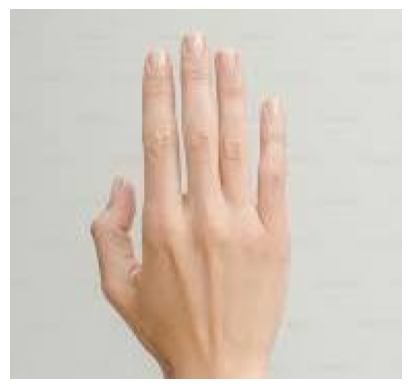

In [48]:
# 41. 새로운 손 사진 불러오기

from PIL import Image
import matplotlib.pyplot as plt

# 실제 파일 이름으로 수정
image = Image.open("new_paper.jpg").convert("RGB")

# 사진 확인
plt.imshow(image)
plt.axis("off")
plt.show()

In [49]:
# 42. 새로운 손 사진 CNN 예측

image_tensor = transform(image).unsqueeze(0).to(device)

model_ft.eval()

with torch.no_grad():
    outputs = model_ft(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_idx = probabilities.argmax(dim=1).item()

class_names = test_dataset.classes

print("AI 예측:", class_names[predicted_idx])
print("예측 점수:", f"{probabilities[0, predicted_idx].item() * 100:.2f}%")

AI 예측: paper
예측 점수: 99.82%


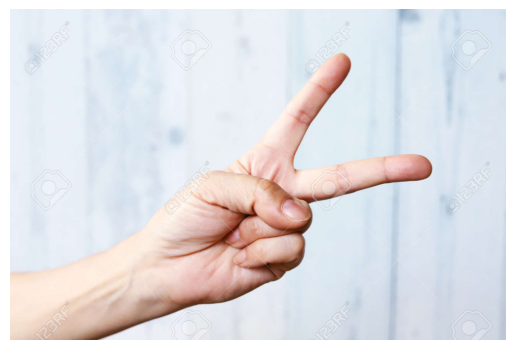

실제 정답: scissors
AI 예측: paper
예측 점수: 56.52%


In [50]:
# 44. 새로운 가위 사진 예측

from PIL import Image
import matplotlib.pyplot as plt
import torch

# 사진 불러오기
image = Image.open("new_scissors.jpg").convert("RGB")

# 사진 확인
plt.imshow(image)
plt.axis("off")
plt.show()

# 모델 입력 형태로 변환
image_tensor = transform(image).unsqueeze(0).to(device)

# Fine-tuning 모델 예측
model_ft.eval()

with torch.no_grad():
    outputs = model_ft(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)
    predicted_idx = probabilities.argmax(dim=1).item()

class_names = test_dataset.classes

print("실제 정답: scissors")
print("AI 예측:", class_names[predicted_idx])
print(f"예측 점수: {probabilities[0, predicted_idx].item() * 100:.2f}%")

In [51]:
# 45. 가위 사진의 클래스별 예측 확률 확인

model_ft.eval()

with torch.no_grad():
    outputs = model_ft(image_tensor)
    probabilities = torch.softmax(outputs, dim=1)[0]

# 클래스별 예측 확률 출력
for i, class_name in enumerate(test_dataset.classes):
    print(f"{class_name}: {probabilities[i].item() * 100:.2f}%")

paper: 56.52%
rock: 0.08%
scissors: 43.40%


> 피키픽 2차 모델, EfficientNet-B0

In [52]:
# 51. EfficientNet-B0 사전학습 모델 불러오기

import torch
import torch.nn as nn
from torchvision import models

# GPU 사용 확인
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("사용 장치:", device)

# ImageNet으로 사전학습된 가중치 불러오기
weights_eff = models.EfficientNet_B0_Weights.IMAGENET1K_V1

# EfficientNet-B0 모델 생성
model_eff = models.efficientnet_b0(weights=weights_eff)

# 기존 분류층 구조 확인
print(model_eff.classifier)

사용 장치: cuda
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1000, bias=True)
)


In [53]:
# 52. EfficientNet-B0 분류층 변경

# 기존 특징 추출층은 동결
for param in model_eff.parameters():
    param.requires_grad = False

# 마지막 분류층을 3개 클래스로 변경
in_features = model_eff.classifier[1].in_features
model_eff.classifier[1] = nn.Linear(in_features, 3)

# GPU로 이동
model_eff = model_eff.to(device)

# 변경된 분류층 확인
print(model_eff.classifier)

# 학습 가능한 파라미터 수 확인
trainable_params = sum(
    p.numel() for p in model_eff.parameters()
    if p.requires_grad
)

print("학습 가능한 파라미터:", trainable_params)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=3, bias=True)
)
학습 가능한 파라미터: 3843


In [54]:
# 53. EfficientNet-B0 전용 데이터셋 준비

from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset

# EfficientNet-B0 사전학습 가중치에 맞는 전처리
eff_transform = weights_eff.transforms()

# 학습·검증·테스트 원본 데이터셋
eff_train_full = datasets.ImageFolder(
    "rps",
    transform=eff_transform
)

eff_val_full = datasets.ImageFolder(
    "rps",
    transform=eff_transform
)

eff_test_dataset = datasets.ImageFolder(
    "rps-test-set",
    transform=eff_transform
)

# 기존 ResNet50과 동일한 데이터 분할 사용
eff_train_dataset = Subset(
    eff_train_full,
    train_indices
)

eff_val_dataset = Subset(
    eff_val_full,
    val_indices
)

print("학습 데이터:", len(eff_train_dataset))
print("검증 데이터:", len(eff_val_dataset))
print("테스트 데이터:", len(eff_test_dataset))

print("클래스:", eff_train_full.classes)

학습 데이터: 2016
검증 데이터: 504
테스트 데이터: 372
클래스: ['paper', 'rock', 'scissors']


In [55]:
# 54. EfficientNet-B0 DataLoader 생성

eff_train_loader = DataLoader(
    eff_train_dataset,
    batch_size=32,
    shuffle=True
)

eff_val_loader = DataLoader(
    eff_val_dataset,
    batch_size=32,
    shuffle=False
)

eff_test_loader = DataLoader(
    eff_test_dataset,
    batch_size=32,
    shuffle=False
)

print("학습 배치:", len(eff_train_loader))
print("검증 배치:", len(eff_val_loader))
print("테스트 배치:", len(eff_test_loader))

학습 배치: 63
검증 배치: 16
테스트 배치: 12


In [56]:
# 55. EfficientNet-B0 학습 설정

import torch
import torch.nn as nn
import torch.optim as optim

# 손실 함수
criterion_eff = nn.CrossEntropyLoss()

# 마지막 분류층만 학습
optimizer_eff = optim.Adam(
    model_eff.classifier[1].parameters(),
    lr=0.001
)

# 학습 횟수
epochs_eff = 5

print("사용 장치:", device)
print("학습 Epoch:", epochs_eff)
print("학습 준비 완료!")

사용 장치: cuda
학습 Epoch: 5
학습 준비 완료!


In [57]:
# 56. EfficientNet-B0 학습 및 검증

train_losses_eff = []
train_accs_eff = []
val_accs_eff = []

for epoch in range(epochs_eff):

    # 특징 추출부는 평가 모드로 유지
    # 분류층은 학습 모드로 설정
    model_eff.eval()
    model_eff.classifier.train()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    # 1. 학습
    for images, labels in eff_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_eff.zero_grad()

        outputs = model_eff(images)
        loss = criterion_eff(outputs, labels)

        loss.backward()
        optimizer_eff.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)

        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = 100 * train_correct / train_total

    # 2. 검증
    model_eff.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in eff_val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_eff(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_acc = 100 * val_correct / val_total

    # 3. 결과 기록
    train_losses_eff.append(train_loss)
    train_accs_eff.append(train_acc)
    val_accs_eff.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs_eff}] | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/5] | Loss: 0.5049 | Train Acc: 88.69% | Val Acc: 98.41%
Epoch [2/5] | Loss: 0.1502 | Train Acc: 99.40% | Val Acc: 99.80%
Epoch [3/5] | Loss: 0.0855 | Train Acc: 99.95% | Val Acc: 100.00%
Epoch [4/5] | Loss: 0.0576 | Train Acc: 99.95% | Val Acc: 100.00%
Epoch [5/5] | Loss: 0.0411 | Train Acc: 100.00% | Val Acc: 100.00%


In [58]:
# 57. EfficientNet-B0 독립 테스트 데이터 평가

model_eff.eval()

test_correct_eff = 0
test_total_eff = 0

with torch.no_grad():
    for images, labels in eff_test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_eff(images)
        predictions = outputs.argmax(dim=1)

        test_correct_eff += (predictions == labels).sum().item()
        test_total_eff += labels.size(0)

test_acc_eff = 100 * test_correct_eff / test_total_eff

print(f"EfficientNet-B0 테스트 정확도: {test_acc_eff:.2f}%")
print(f"정답 개수: {test_correct_eff}/{test_total_eff}")

EfficientNet-B0 테스트 정확도: 80.65%
정답 개수: 300/372


In [59]:
# 58. EfficientNet-B0 클래스별 정확도

class_correct_eff = [0, 0, 0]
class_total_eff = [0, 0, 0]

model_eff.eval()

with torch.no_grad():
    for images, labels in eff_test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_eff(images)
        predictions = outputs.argmax(dim=1)

        for label, pred in zip(labels, predictions):
            idx = label.item()

            class_total_eff[idx] += 1

            if label == pred:
                class_correct_eff[idx] += 1

for i, name in enumerate(eff_test_dataset.classes):
    acc = 100 * class_correct_eff[i] / class_total_eff[i]

    print(
        f"{name}: {acc:.2f}% "
        f"({class_correct_eff[i]}/{class_total_eff[i]})"
    )

paper: 41.94% (52/124)
rock: 100.00% (124/124)
scissors: 100.00% (124/124)


In [60]:
# 59. ResNet50 + EfficientNet-B0 앙상블 테스트

import torch

model_ft.eval()
model_eff.eval()

ensemble_correct = 0
ensemble_total = 0

# 앙상블 가중치 (임시 실험값)
weight_resnet = 0.7
weight_effnet = 0.3

with torch.no_grad():
    for images, labels in eff_test_loader:

        labels = labels.to(device)

        # EfficientNet 전처리가 적용된 이미지
        images_eff = images.to(device)

        # ResNet50은 별도 전처리 필요!
        # 따라서 이 루프의 images_eff를 그대로 사용하면
        # 서로 다른 전처리 조건에서 평가하게 됨.

In [61]:
# 59. ResNet50 + EfficientNet-B0 앙상블 평가

import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

# 두 모델의 전처리를 각각 적용하는 데이터셋
class EnsembleDataset(Dataset):
    def __init__(self, samples, transform_resnet, transform_eff):
        self.samples = samples
        self.transform_resnet = transform_resnet
        self.transform_eff = transform_eff

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        image = Image.open(path).convert("RGB")

        image_resnet = self.transform_resnet(image)
        image_eff = self.transform_eff(image)

        return image_resnet, image_eff, label


# 기존 테스트 이미지 372장 사용
ensemble_dataset = EnsembleDataset(
    eff_test_dataset.samples,
    transform,
    eff_transform
)

ensemble_loader = DataLoader(
    ensemble_dataset,
    batch_size=32,
    shuffle=False
)

# 모델 평가 모드
model_ft.eval()
model_eff.eval()

# 임시 앙상블 가중치
weight_resnet = 0.7
weight_effnet = 0.3

# 클래스별 결과 저장
class_correct = [0, 0, 0]
class_total = [0, 0, 0]

with torch.no_grad():
    for images_resnet, images_eff, labels in ensemble_loader:

        images_resnet = images_resnet.to(device)
        images_eff = images_eff.to(device)
        labels = labels.to(device)

        # 두 모델의 예측 확률
        outputs_resnet = model_ft(images_resnet)
        outputs_eff = model_eff(images_eff)

        probs_resnet = torch.softmax(outputs_resnet, dim=1)
        probs_eff = torch.softmax(outputs_eff, dim=1)

        # 가중 앙상블
        ensemble_probs = (
            weight_resnet * probs_resnet
            + weight_effnet * probs_eff
        )

        predictions = ensemble_probs.argmax(dim=1)

        # 클래스별 정답 개수
        for label, pred in zip(labels, predictions):
            idx = label.item()
            class_total[idx] += 1

            if label == pred:
                class_correct[idx] += 1


# 전체 정확도
total_correct = sum(class_correct)
total_images = sum(class_total)
ensemble_acc = 100 * total_correct / total_images

print("===== 앙상블 평가 결과 =====")
print(f"ResNet50 가중치: {weight_resnet}")
print(f"EfficientNet 가중치: {weight_effnet}")
print(f"전체 정확도: {ensemble_acc:.2f}%")
print(f"정답 개수: {total_correct}/{total_images}")

print("\n===== 클래스별 정확도 =====")

for i, name in enumerate(eff_test_dataset.classes):
    acc = 100 * class_correct[i] / class_total[i]
    print(f"{name}: {acc:.2f}% ({class_correct[i]}/{class_total[i]})")

===== 앙상블 평가 결과 =====
ResNet50 가중치: 0.7
EfficientNet 가중치: 0.3
전체 정확도: 96.51%
정답 개수: 359/372

===== 클래스별 정확도 =====
paper: 98.39% (122/124)
rock: 100.00% (124/124)
scissors: 91.13% (113/124)


In [62]:
# 60. EfficientNet-B0 및 앙상블 설정 저장

import torch
import os

os.makedirs("models", exist_ok=True)

# EfficientNet-B0 모델 저장
torch.save({
    "model_state_dict": model_eff.state_dict(),
    "class_to_idx": eff_test_dataset.class_to_idx,
    "model_name": "EfficientNet-B0",
    "epochs": epochs_eff
}, "models/pikipick_efficientnet_b0_v1.pth")

# 앙상블 가중치와 실험 결과 저장
torch.save({
    "resnet_weight": 0.7,
    "efficientnet_weight": 0.3,
    "class_to_idx": eff_test_dataset.class_to_idx,
    "test_accuracy": ensemble_acc,
    "test_correct": total_correct,
    "test_total": total_images
}, "models/pikipick_ensemble_config.pth")

print("EfficientNet-B0 저장 완료!")
print("앙상블 설정 저장 완료!")

EfficientNet-B0 저장 완료!
앙상블 설정 저장 완료!


In [63]:
# 61. 앙상블 가중치별 정확도 비교 + 공동 최고 비율 확인

import torch
from torch.utils.data import DataLoader

# 1. 기존 검증 데이터 504장 준비
val_samples = [
    eff_val_full.samples[i]
    for i in val_indices
]

ensemble_val_dataset = EnsembleDataset(
    val_samples,
    transform,
    eff_transform
)

ensemble_val_loader = DataLoader(
    ensemble_val_dataset,
    batch_size=32,
    shuffle=False
)

# 2. 두 모델 평가 모드
model_ft.eval()
model_eff.eval()

resnet_probs_all = []
effnet_probs_all = []
labels_all = []

# 3. 두 모델의 예측 확률 계산
with torch.no_grad():
    for imgs_res, imgs_eff, labels in ensemble_val_loader:

        imgs_res = imgs_res.to(device)
        imgs_eff = imgs_eff.to(device)

        # ResNet50 예측
        resnet_probs = torch.softmax(
            model_ft(imgs_res), dim=1
        )

        # EfficientNet-B0 예측
        effnet_probs = torch.softmax(
            model_eff(imgs_eff), dim=1
        )

        resnet_probs_all.append(resnet_probs.cpu())
        effnet_probs_all.append(effnet_probs.cpu())
        labels_all.append(labels)

resnet_probs_all = torch.cat(resnet_probs_all)
effnet_probs_all = torch.cat(effnet_probs_all)
labels_all = torch.cat(labels_all)

# 4. 앙상블 가중치별 정확도 비교
results = []

print("===== 앙상블 가중치 비교 =====")

for w in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:

    ensemble_probs = (
        w * resnet_probs_all
        + (1 - w) * effnet_probs_all
    )

    predictions = ensemble_probs.argmax(dim=1)

    correct = (predictions == labels_all).sum().item()
    accuracy = 100 * correct / len(labels_all)

    results.append((w, accuracy))

    print(
        f"ResNet {w:.1f} : EfficientNet {1-w:.1f} "
        f"→ {accuracy:.2f}% ({correct}/{len(labels_all)})"
    )

# 5. 최고 정확도 및 공동 1위 확인
best_accuracy = max(acc for w, acc in results)

best_weights = [
    w for w, acc in results
    if acc == best_accuracy
]

print("\n===== 최종 비교 결과 =====")
print(f"최고 검증 정확도: {best_accuracy:.2f}%")
print(f"공동 최고 비율: {len(best_weights)}개")

for w in best_weights:
    print(f"ResNet {w:.1f} : EfficientNet {1-w:.1f}")

# 6. 기존 앙상블 가중치 유지
weight_resnet = 0.7
weight_effnet = 0.3

print("\n===== 현재 채택한 실험 비율 =====")
print(f"ResNet50: {weight_resnet:.1f}")
print(f"EfficientNet-B0: {weight_effnet:.1f}")
print("선정 이유: 검증 정확도가 모두 같아 기존 비율 유지")

===== 앙상블 가중치 비교 =====
ResNet 0.3 : EfficientNet 0.7 → 100.00% (504/504)
ResNet 0.4 : EfficientNet 0.6 → 100.00% (504/504)
ResNet 0.5 : EfficientNet 0.5 → 100.00% (504/504)
ResNet 0.6 : EfficientNet 0.4 → 100.00% (504/504)
ResNet 0.7 : EfficientNet 0.3 → 100.00% (504/504)
ResNet 0.8 : EfficientNet 0.2 → 100.00% (504/504)
ResNet 0.9 : EfficientNet 0.1 → 100.00% (504/504)

===== 최종 비교 결과 =====
최고 검증 정확도: 100.00%
공동 최고 비율: 7개
ResNet 0.3 : EfficientNet 0.7
ResNet 0.4 : EfficientNet 0.6
ResNet 0.5 : EfficientNet 0.5
ResNet 0.6 : EfficientNet 0.4
ResNet 0.7 : EfficientNet 0.3
ResNet 0.8 : EfficientNet 0.2
ResNet 0.9 : EfficientNet 0.1

===== 현재 채택한 실험 비율 =====
ResNet50: 0.7
EfficientNet-B0: 0.3
선정 이유: 검증 정확도가 모두 같아 기존 비율 유지


In [64]:
# 62. EfficientNet-B0 Fine-tuning 모델 준비

import copy
import torch
import torch.nn as nn
import torch.optim as optim

# 기존 EfficientNet-B0 복사
model_eff_ft = copy.deepcopy(model_eff)

# 1. 모든 파라미터 동결
for param in model_eff_ft.parameters():
    param.requires_grad = False

# 2. 마지막 특징 추출 블록 학습 허용
for param in model_eff_ft.features[-1].parameters():
    param.requires_grad = True

# 3. 마지막 분류층 학습 허용
for param in model_eff_ft.classifier.parameters():
    param.requires_grad = True

# 4. GPU로 이동
model_eff_ft = model_eff_ft.to(device)

# 5. 학습 가능한 파라미터 수 확인
trainable_params = sum(
    p.numel()
    for p in model_eff_ft.parameters()
    if p.requires_grad
)

print("사용 장치:", device)
print("학습 가능한 파라미터:", trainable_params)
print("Fine-tuning 모델 준비 완료!")

사용 장치: cuda
학습 가능한 파라미터: 416003
Fine-tuning 모델 준비 완료!


In [65]:
# 63. EfficientNet-B0 Fine-tuning 학습 설정

# 손실 함수
criterion_eff_ft = nn.CrossEntropyLoss()

# 학습률을 다르게 적용
optimizer_eff_ft = optim.Adam([
    {
        "params": model_eff_ft.features[-1].parameters(),
        "lr": 0.00001
    },
    {
        "params": model_eff_ft.classifier.parameters(),
        "lr": 0.0001
    }
])

# 학습 횟수
epochs_eff_ft = 5

print("Fine-tuning Epoch:", epochs_eff_ft)
print("특징 추출층 학습률:", 0.00001)
print("분류층 학습률:", 0.0001)
print("학습 준비 완료!")

Fine-tuning Epoch: 5
특징 추출층 학습률: 1e-05
분류층 학습률: 0.0001
학습 준비 완료!


In [66]:
# 64. EfficientNet-B0 Fine-tuning

train_losses_eff_ft = []
train_accs_eff_ft = []
val_accs_eff_ft = []

for epoch in range(epochs_eff_ft):

    # 사전학습된 특징 추출층은 평가 모드 유지
    model_eff_ft.eval()

    # 마지막 특징 추출 블록과 분류층만 학습 모드
    model_eff_ft.features[-1].train()
    model_eff_ft.classifier.train()

    # BatchNorm 통계값 고정
    for module in model_eff_ft.features[-1].modules():
        if isinstance(module, nn.BatchNorm2d):
            module.eval()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    # 1. 학습
    for images, labels in eff_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_eff_ft.zero_grad()

        outputs = model_eff_ft(images)
        loss = criterion_eff_ft(outputs, labels)

        loss.backward()
        optimizer_eff_ft.step()

        running_loss += loss.item() * labels.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss = running_loss / train_total
    train_acc = 100 * train_correct / train_total

    # 2. 검증
    model_eff_ft.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in eff_val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_eff_ft(images)
            predictions = outputs.argmax(dim=1)

            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_acc = 100 * val_correct / val_total

    # 3. 결과 기록
    train_losses_eff_ft.append(train_loss)
    train_accs_eff_ft.append(train_acc)
    val_accs_eff_ft.append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs_eff_ft}] | "
        f"Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2f}% | "
        f"Val Acc: {val_acc:.2f}%"
    )

Epoch [1/5] | Loss: 0.0318 | Train Acc: 100.00% | Val Acc: 100.00%
Epoch [2/5] | Loss: 0.0230 | Train Acc: 100.00% | Val Acc: 100.00%
Epoch [3/5] | Loss: 0.0175 | Train Acc: 99.95% | Val Acc: 100.00%
Epoch [4/5] | Loss: 0.0140 | Train Acc: 99.95% | Val Acc: 100.00%
Epoch [5/5] | Loss: 0.0117 | Train Acc: 99.95% | Val Acc: 100.00%


In [67]:
# 65. EfficientNet-B0 Fine-tuning 모델 저장

import os
import torch

os.makedirs("models", exist_ok=True)

save_path = "models/pikipick_efficientnet_b0_ft_v1.pth"

torch.save({
    "model_state_dict": model_eff_ft.state_dict(),
    "class_to_idx": eff_test_dataset.class_to_idx,
    "model_name": "EfficientNet-B0 Fine-tuning",
    "epochs": epochs_eff_ft,
    "train_accuracy": train_accs_eff_ft[-1],
    "val_accuracy": val_accs_eff_ft[-1]
}, save_path)

print("Fine-tuning 모델 저장 완료!")
print("저장 경로:", os.path.abspath(save_path))

Fine-tuning 모델 저장 완료!
저장 경로: c:\Users\mbc\rock\models\pikipick_efficientnet_b0_ft_v1.pth


In [68]:
# 66. EfficientNet-B0 Fine-tuning 성능 평가

model_eff_ft.eval()

class_correct_ft = [0, 0, 0]
class_total_ft = [0, 0, 0]

with torch.no_grad():
    for images, labels in eff_test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model_eff_ft(images)
        predictions = outputs.argmax(dim=1)

        for label, pred in zip(labels, predictions):
            idx = label.item()
            class_total_ft[idx] += 1

            if label.item() == pred.item():
                class_correct_ft[idx] += 1

# 전체 정확도 계산
total_correct_ft = sum(class_correct_ft)
total_images_ft = sum(class_total_ft)
test_acc_eff_ft = 100 * total_correct_ft / total_images_ft

print("===== EfficientNet-B0 Fine-tuning 결과 =====")
print(f"전체 정확도: {test_acc_eff_ft:.2f}%")
print(f"정답 개수: {total_correct_ft}/{total_images_ft}")

print("\n===== 클래스별 정확도 =====")

for i, name in enumerate(eff_test_dataset.classes):
    acc = 100 * class_correct_ft[i] / class_total_ft[i]

    print(
        f"{name}: {acc:.2f}% "
        f"({class_correct_ft[i]}/{class_total_ft[i]})"
    )

===== EfficientNet-B0 Fine-tuning 결과 =====
전체 정확도: 85.48%
정답 개수: 318/372

===== 클래스별 정확도 =====
paper: 56.45% (70/124)
rock: 100.00% (124/124)
scissors: 100.00% (124/124)


In [69]:
# 67. ResNet50 + Fine-tuning EfficientNet-B0 앙상블 평가

import torch

model_ft.eval()
model_eff_ft.eval()

# 기존과 동일한 가중치
weight_resnet = 0.7
weight_effnet = 0.3

class_correct_new = [0, 0, 0]
class_total_new = [0, 0, 0]

with torch.no_grad():
    for images_resnet, images_eff, labels in ensemble_loader:

        images_resnet = images_resnet.to(device)
        images_eff = images_eff.to(device)
        labels = labels.to(device)

        # ResNet50 예측 확률
        probs_resnet = torch.softmax(
            model_ft(images_resnet), dim=1
        )

        # Fine-tuning EfficientNet 예측 확률
        probs_eff = torch.softmax(
            model_eff_ft(images_eff), dim=1
        )

        # 새로운 앙상블
        ensemble_probs = (
            weight_resnet * probs_resnet
            + weight_effnet * probs_eff
        )

        predictions = ensemble_probs.argmax(dim=1)

        for label, pred in zip(labels, predictions):
            idx = label.item()
            class_total_new[idx] += 1

            if label.item() == pred.item():
                class_correct_new[idx] += 1

# 전체 정확도
total_correct_new = sum(class_correct_new)
total_images_new = sum(class_total_new)

ensemble_acc_new = 100 * total_correct_new / total_images_new

print("===== 새로운 앙상블 평가 결과 =====")
print("ResNet50 + EfficientNet-B0 Fine-tuning")
print(f"전체 정확도: {ensemble_acc_new:.2f}%")
print(f"정답 개수: {total_correct_new}/{total_images_new}")

print("\n===== 클래스별 정확도 =====")

for i, name in enumerate(eff_test_dataset.classes):
    acc = 100 * class_correct_new[i] / class_total_new[i]
    print(
        f"{name}: {acc:.2f}% "
        f"({class_correct_new[i]}/{class_total_new[i]})"
    )

print("\n===== 기존 앙상블과 비교 =====")
print("기존 앙상블: 96.51%")
print(f"새로운 앙상블: {ensemble_acc_new:.2f}%")
print(f"정확도 변화: {ensemble_acc_new - 96.51:+.2f}%p")

===== 새로운 앙상블 평가 결과 =====
ResNet50 + EfficientNet-B0 Fine-tuning
전체 정확도: 97.04%
정답 개수: 361/372

===== 클래스별 정확도 =====
paper: 99.19% (123/124)
rock: 100.00% (124/124)
scissors: 91.94% (114/124)

===== 기존 앙상블과 비교 =====
기존 앙상블: 96.51%
새로운 앙상블: 97.04%
정확도 변화: +0.53%p


In [70]:
# 68. 앙상블 오분류 원인 분석

import torch

model_ft.eval()
model_eff_ft.eval()

class_names = eff_test_dataset.classes
error_results = []

with torch.no_grad():
    sample_idx = 0

    for images_resnet, images_eff, labels in ensemble_loader:

        images_resnet = images_resnet.to(device)
        images_eff = images_eff.to(device)
        labels = labels.to(device)

        # 1. 각 모델 예측 확률
        probs_resnet = torch.softmax(
            model_ft(images_resnet), dim=1
        )

        probs_eff = torch.softmax(
            model_eff_ft(images_eff), dim=1
        )

        # 2. 앙상블 예측 확률
        probs_ensemble = (
            0.7 * probs_resnet +
            0.3 * probs_eff
        )

        # 3. 각 모델의 예측 결과
        pred_resnet = probs_resnet.argmax(dim=1)
        pred_eff = probs_eff.argmax(dim=1)
        pred_ensemble = probs_ensemble.argmax(dim=1)

        # 4. 앙상블이 틀린 경우만 기록
        for i in range(len(labels)):

            true_idx = labels[i].item()
            ensemble_idx = pred_ensemble[i].item()

            if true_idx != ensemble_idx:
                error_results.append({
                    "번호": sample_idx + i,
                    "실제": class_names[true_idx],
                    "ResNet50": class_names[pred_resnet[i].item()],
                    "EfficientNet": class_names[pred_eff[i].item()],
                    "앙상블": class_names[ensemble_idx],
                    "ResNet_정답확률": round(
                        probs_resnet[i, true_idx].item() * 100, 2
                    ),
                    "EffNet_정답확률": round(
                        probs_eff[i, true_idx].item() * 100, 2
                    )
                })

        sample_idx += len(labels)

# 5. 분석 결과 출력
import pandas as pd

error_df = pd.DataFrame(error_results)

print("앙상블 오분류 개수:", len(error_df))
print("\n===== 오분류 상세 분석 =====")

display(error_df)

앙상블 오분류 개수: 11

===== 오분류 상세 분석 =====


,번호,실제,ResNet50,EfficientNet,앙상블,ResNet_정답확률,EffNet_정답확률
0,88,paper,rock,paper,rock,43.00,50.41
1,310,scissors,paper,scissors,paper,9.43,84.94
2,311,scissors,paper,scissors,paper,11.46,85.46
3,312,scissors,paper,scissors,paper,25.09,92.46
4,313,scissors,paper,scissors,paper,16.39,72.49
5,314,scissors,paper,scissors,paper,4.11,68.34
6,315,scissors,paper,scissors,paper,17.72,79.41
7,316,scissors,paper,scissors,paper,29.28,59.55
8,321,scissors,paper,scissors,paper,13.94,94.67
9,322,scissors,paper,scissors,paper,10.08,95.97


In [71]:
# 69. 두 모델이 서로 다르게 예측한 이미지 분석

import torch
import pandas as pd

model_ft.eval()
model_eff_ft.eval()

results = []

with torch.no_grad():
    for images_res, images_eff, labels in ensemble_loader:

        images_res = images_res.to(device)
        images_eff = images_eff.to(device)
        labels = labels.to(device)

        probs_res = torch.softmax(model_ft(images_res), dim=1)
        probs_eff = torch.softmax(model_eff_ft(images_eff), dim=1)

        pred_res = probs_res.argmax(dim=1)
        pred_eff = probs_eff.argmax(dim=1)

        pred_ens = (
            0.7 * probs_res + 0.3 * probs_eff
        ).argmax(dim=1)

        for true, res, eff, ens in zip(
            labels, pred_res, pred_eff, pred_ens
        ):
            if res.item() != eff.item():
                results.append({
                    "실제": eff_test_dataset.classes[true.item()],
                    "ResNet50": eff_test_dataset.classes[res.item()],
                    "EfficientNet": eff_test_dataset.classes[eff.item()],
                    "앙상블": eff_test_dataset.classes[ens.item()],
                    "ResNet 정답": res.item() == true.item(),
                    "EfficientNet 정답": eff.item() == true.item(),
                    "앙상블 정답": ens.item() == true.item()
                })

df_disagree = pd.DataFrame(results)

print("===== 두 모델 예측 불일치 분석 =====")
print("불일치 이미지:", len(df_disagree))

print("\nResNet50만 정답:",
      ((df_disagree["ResNet 정답"]) &
       (~df_disagree["EfficientNet 정답"])).sum())

print("EfficientNet만 정답:",
      ((~df_disagree["ResNet 정답"]) &
       (df_disagree["EfficientNet 정답"])).sum())

print("두 모델 모두 오답:",
      ((~df_disagree["ResNet 정답"]) &
       (~df_disagree["EfficientNet 정답"])).sum())

print("\n앙상블이 틀린 이미지:",
      (~df_disagree["앙상블 정답"]).sum())

display(df_disagree)

===== 두 모델 예측 불일치 분석 =====
불일치 이미지: 75

ResNet50만 정답: 54
EfficientNet만 정답: 21
두 모델 모두 오답: 0

앙상블이 틀린 이미지: 11


,실제,ResNet50,EfficientNet,앙상블,ResNet 정답,EfficientNet 정답,앙상블 정답
0,paper,paper,rock,paper,True,False,True
1,paper,paper,rock,paper,True,False,True
2,paper,paper,rock,paper,True,False,True
3,paper,paper,rock,paper,True,False,True
4,paper,paper,rock,paper,True,False,True
...,...,...,...,...,...,...,...
70,scissors,paper,scissors,scissors,False,True,True
71,scissors,paper,scissors,paper,False,True,False
72,scissors,paper,scissors,scissors,False,True,True
73,scissors,paper,scissors,scissors,False,True,True


===== 최종 앙상블 모델 성능 평가 =====
Accuracy : 97.04%
Precision: 97.23%
Recall   : 97.04%
F1-Score : 97.04%

===== 클래스별 성능 평가 =====
              precision    recall  f1-score   support

       paper     0.9248    0.9919    0.9572       124
        rock     0.9920    1.0000    0.9960       124
    scissors     1.0000    0.9194    0.9580       124

    accuracy                         0.9704       372
   macro avg     0.9723    0.9704    0.9704       372
weighted avg     0.9723    0.9704    0.9704       372



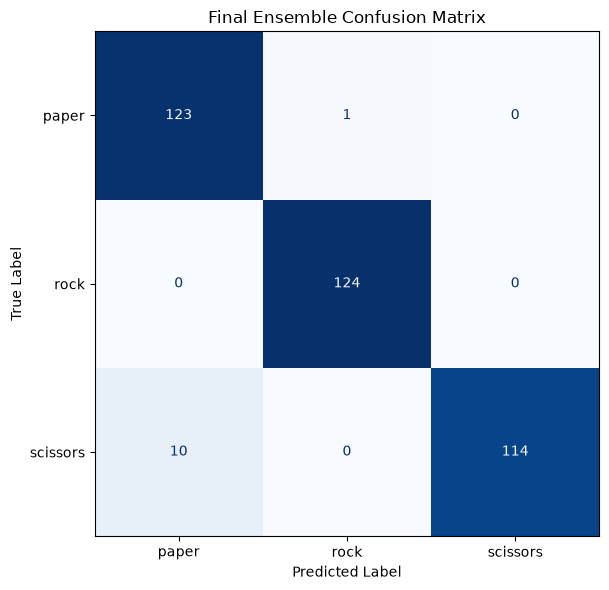

In [72]:
# Q4-1. 최종 모델 성능 평가
# ResNet50 FT + EfficientNet-B0 FT (70:30 앙상블)

import torch
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# 1. 최종 모델 평가 모드
model_ft.eval()
model_eff_ft.eval()

# 2. 앙상블 결합 비율
weight_resnet = 0.7
weight_effnet = 0.3

# 3. 실제 정답과 예측 결과 저장
y_true_final = []
y_pred_final = []

with torch.no_grad():

    for images_resnet, images_eff, labels in ensemble_loader:

        images_resnet = images_resnet.to(device)
        images_eff = images_eff.to(device)

        # ResNet50 예측 확률
        probs_resnet = torch.softmax(
            model_ft(images_resnet), dim=1
        )

        # EfficientNet-B0 Fine-tuning 예측 확률
        probs_effnet = torch.softmax(
            model_eff_ft(images_eff), dim=1
        )

        # Soft Voting 앙상블
        ensemble_probs = (
            weight_resnet * probs_resnet
            + weight_effnet * probs_effnet
        )

        predictions = ensemble_probs.argmax(dim=1)

        y_true_final.extend(labels.tolist())
        y_pred_final.extend(predictions.cpu().tolist())


# 4. 최종 성능 지표 계산
accuracy = accuracy_score(y_true_final, y_pred_final)
precision = precision_score(
    y_true_final, y_pred_final,
    average="macro", zero_division=0
)
recall = recall_score(
    y_true_final, y_pred_final,
    average="macro", zero_division=0
)
f1 = f1_score(
    y_true_final, y_pred_final,
    average="macro", zero_division=0
)

print("===== 최종 앙상블 모델 성능 평가 =====")
print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-Score : {f1 * 100:.2f}%")


# 5. 클래스별 성능 지표
class_names = eff_test_dataset.classes

print("\n===== 클래스별 성능 평가 =====")
print(
    classification_report(
        y_true_final,
        y_pred_final,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


# 6. 혼동 행렬 생성
cm_final = confusion_matrix(
    y_true_final,
    y_pred_final,
    labels=list(range(len(class_names)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_final,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(7, 6))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False
)

plt.title("Final Ensemble Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()